# Implementasi Genetic Algorithm (GA)
# Marsa Naufal - 04231047
## 1. Hyperparameter Tuning · 2. Vehicle Routing Problem (VRP)

### Cara menggunakan

1. Pilih kernel Python dari `.venv` pada folder ini.
2. Jika library belum tersedia, aktifkan baris `%pip install` di bawah dengan menghapus tanda `#`.
3. Pilih **Restart Kernel → Run All**, atau jalankan sel berurutan dari atas ke bawah.
4. Baca penjelasan sebelum kode, kemudian lihat tabel dan grafik hasilnya.


### 0.1 Siapkan Library

`numpy` mengolah angka, `pandas` membuat tabel, `matplotlib` menggambar,
`scikit-learn` menyediakan model dan data, sedangkan `pygad` menjalankan GA.
Instalasi hanya diperlukan sekali pada lingkungan Python yang dipakai.

In [ ]:
import sys
from time import perf_counter
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pygad
from IPython.display import display, Markdown
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED_DATA = 42
SEEDS = [11, 22, 33]
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_columns', 12)
print('Python:', sys.version.split()[0])
display(pd.DataFrame({
    'Library': ['numpy', 'pandas', 'matplotlib', 'scikit-learn', 'pygad'],
    'Versi': [version(p) for p in ['numpy', 'pandas', 'matplotlib', 'scikit-learn', 'pygad']],
}))

Python: 3.13.15


,Library,Versi
0,numpy,2.5.3
1,pandas,3.0.5
2,matplotlib,3.11.2
3,scikit-learn,1.9.1
4,pygad,3.7.0


# 1. Hyperparameter Tuning

### 1.1 Pahami masalahnya

Kita ingin model menebak **kelas wine** berdasarkan hasil pengukuran kandungannya.
Dataset Wine bawaan scikit-learn mempunyai 178 sampel, 13 fitur, dan 3 kelas.

Modelnya adalah **Decision Tree**, yaitu pohon pertanyaan: “Apakah nilainya lebih besar dari ini?”
Jawaban mengarahkan kita ke cabang berikutnya sampai mendapat prediksi.

**Hyperparameter** adalah pengaturan sebelum model belajar. Contohnya, seberapa dalam pohonnya boleh tumbuh.
GA akan mencoba banyak paket pengaturan dan memilih yang mendapat nilai validasi tinggi.

Ada **dua tingkat tuning** di notebook ini:

1. GA mencari **hyperparameter model**, seperti `max_depth`.
2. Kita menguji **hyperparameter GA**, yaitu peluang mutasi 0.05, 0.20, dan 0.50.

Jadi, pengaturan model dan pengaturan mesin pencarinya adalah dua hal berbeda.

### 1.2 Siapkan data latihan dan ujian

Anggap data latihan seperti soal latihan, sedangkan data uji seperti soal ujian yang disimpan di amplop.
Kita mengambil 80% untuk latihan dan 20% untuk ujian. `stratify` menjaga proporsi tiap kelas.

Saat tuning, hanya data latihan yang dibagi lagi menjadi **4 lipatan (fold)**:
latih pada 3 bagian, nilai pada 1 bagian, lalu ganti bagian penilaiannya. Rata-rata 4 nilai menjadi fitness.
Pembagiannya tetap sama untuk semua kandidat agar perbandingannya konsisten.
**Data uji belum dibuka saat memilih model atau pengaturan GA.**

In [2]:
wine = load_wine(as_frame=True)
X = wine.data
y = wine.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED_DATA
)
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED_DATA)
CV_SPLITS = list(cv.split(X_train, y_train))

print(f'Data latihan: {len(X_train)} | Data uji: {len(X_test)} | Fitur: {X.shape[1]}')
display(X_train.head().round(2))
display(y_train.value_counts().sort_index().rename_axis('Kelas').to_frame('Jumlah latihan'))
assert set(X_train.index).isdisjoint(X_test.index)

Data latihan: 142 | Data uji: 36 | Fitur: 13


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,...,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
36,13.28,1.64,2.84,15.5,110.0,2.60,...,0.34,1.36,4.60,1.09,2.78,880.0
30,13.73,1.50,2.70,22.5,101.0,3.00,...,0.29,2.38,5.70,1.19,2.71,1285.0
26,13.39,1.77,2.62,16.1,93.0,2.85,...,0.34,1.45,4.80,0.92,3.22,1195.0
12,13.75,1.73,2.41,16.0,89.0,2.60,...,0.29,1.81,5.60,1.15,2.90,1320.0
148,13.32,3.24,2.38,21.5,92.0,1.93,...,0.45,1.25,8.42,0.55,1.62,650.0


,Jumlah latihan
Kelas,
0,47
1,57
2,38


### 1.3 Tentukan pembanding awal (baseline)

Sebelum memakai GA, kita ukur Decision Tree dengan pengaturan bawaan.
Ini seperti mencicipi resep awal sebelum mencoba resep baru.

**Akurasi = jumlah tebakan benar ÷ jumlah semua tebakan.** Nilai 0.90 berarti 90% tebakan benar.
Tabel berikut berisi nilai validasi, bukan nilai ujian akhir.

In [3]:
baseline_model = DecisionTreeClassifier(random_state=SEED_DATA)
baseline_cv_scores = cross_val_score(
    baseline_model, X_train, y_train, cv=CV_SPLITS, scoring='accuracy', n_jobs=1
)
baseline_cv = float(baseline_cv_scores.mean())
display(pd.DataFrame({
    'Fold': np.arange(1, 5), 'Akurasi validasi': baseline_cv_scores
}).round(4))
print(f'Rata-rata validasi baseline: {baseline_cv:.2%}')

,Fold,Akurasi validasi
0,1,0.8333
1,2,0.9167
2,3,0.9143
3,4,0.8571


Rata-rata validasi baseline: 88.04%


### 1.4 Ubah pengaturan menjadi kromosom

Satu kromosom mempunyai **5 gen**. Isinya adalah nomor pilihan pada tabel, dimulai dari **0**.
Misalnya gen pertama bernilai `2` berarti memilih pilihan ketiga: `max_depth=3`.
Nomor pilihan dibaca kembali menjadi pengaturan asli oleh fungsi `decode_model`.

| Hyperparameter model | Pilihan | Arti sederhana |
|---|---|---|
| `max_depth` | 1, 2, 3, 4, 5, 6, 8, None | Batas jumlah tingkat pertanyaan; None = tanpa batas |
| `min_samples_split` | 2, 4, 6, 10 | Minimal sampel agar satu simpul boleh dipecah |
| `min_samples_leaf` | 1, 2, 3, 5 | Minimal sampel pada ujung cabang |
| `max_features` | None, sqrt, log2 | Banyak fitur yang dipertimbangkan tiap pemisahan; None = semua |
| `criterion` | gini, entropy | Cara mengukur seberapa rapi pemisahan kelas |

Decision Tree tidak membutuhkan standardisasi fitur untuk contoh ini.

In [4]:
MODEL_SPACE = {
    'max_depth': [1, 2, 3, 4, 5, 6, 8, None],
    'min_samples_split': [2, 4, 6, 10],
    'min_samples_leaf': [1, 2, 3, 5],
    'max_features': [None, 'sqrt', 'log2'],
    'criterion': ['gini', 'entropy'],
}
MODEL_KEYS = list(MODEL_SPACE)
MODEL_GENE_SPACE = [list(range(len(v))) for v in MODEL_SPACE.values()]

def decode_model(chromosome):
    return {name: MODEL_SPACE[name][int(gene)]
            for name, gene in zip(MODEL_KEYS, chromosome)}

example_model = [2, 0, 0, 0, 1]
print('Contoh kromosom:', example_model)
print('Arti kromosom:', decode_model(example_model))
print('Jumlah kombinasi yang mungkin:', int(np.prod([len(v) for v in MODEL_SPACE.values()])))

Contoh kromosom: [2, 0, 0, 0, 1]
Arti kromosom: {'max_depth': 3, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': None, 'criterion': 'entropy'}
Jumlah kombinasi yang mungkin: 768


### 1.5 Buat fitness dan mesin GA

Untuk setiap kandidat: baca kromosom → buat model → hitung rata-rata akurasi 4 fold.
Fitness lebih besar berarti kandidat lebih baik.

Pengaturan tetap: **16 kandidat, 15 generasi, turnamen 3 kandidat, 2 elit**, dan crossover uniform.
Pada crossover uniform, setiap gen anak dapat berasal dari salah satu orang tuanya.
Mutasi acak mengganti pilihan gen; `mutation_probability` berlaku **per gen**.

`cache` seperti buku catatan: pengaturan yang sama tidak perlu dilatih ulang dalam satu percobaan.
Buku catatan dibuat baru pada setiap percobaan. Kita juga mencatat jumlah kandidat unik dan waktu proses.

In [5]:
def run_model_ga(mutation_probability, seed):
    cache = {}
    started = perf_counter()

    def fitness_model(ga_instance, solution, solution_idx):
        key = tuple(int(g) for g in solution)
        if key not in cache:
            model = DecisionTreeClassifier(**decode_model(key), random_state=SEED_DATA)
            scores = cross_val_score(
                model, X_train, y_train, cv=CV_SPLITS, scoring='accuracy', n_jobs=1
            )
            cache[key] = float(scores.mean())
        return cache[key]

    ga = pygad.GA(
        num_generations=15, sol_per_pop=16, num_parents_mating=8,
        num_genes=len(MODEL_KEYS), gene_type=int, gene_space=MODEL_GENE_SPACE,
        fitness_func=fitness_model,
        parent_selection_type='tournament', K_tournament=3, keep_elitism=2,
        crossover_type='uniform', mutation_type='random',
        mutation_probability=mutation_probability, random_seed=seed,
    )
    ga.run()
    solution, fitness, _ = ga.best_solution()
    return {
        'mutasi': mutation_probability, 'seed': seed,
        'cv_terbaik': float(fitness), 'kandidat_unik': len(cache),
        'fit_model': len(cache) * len(CV_SPLITS),
        'detik': perf_counter() - started,
        'params': decode_model(solution), 'kromosom': solution.copy(),
        'history': np.asarray(ga.best_solutions_fitness, dtype=float),
    }

### 1.6 Uji coba tuning hyperparameter GA

Kita coba peluang mutasi **5%, 20%, dan 50%**, masing-masing dengan **3 seed**: total **9 percobaan**.
Populasi dan jumlah generasi dibuat sama. Seed yang sama juga memberi populasi awal yang sama
untuk setiap tingkat mutasi pada kasus ini.

Mutasi kecil mengubah sedikit gen; mutasi besar mencoba lebih banyak perubahan.
Belum tentu salah satunya selalu menang, jadi kita ukur hasilnya.

**Aturan memilih sebelum melihat hasil:** pilih tingkat mutasi dengan rata-rata CV terbaik;
jika seri, pilih simpangan baku lebih kecil, lalu tingkat mutasi lebih kecil.
Dari konfigurasi itu, ambil run dengan CV terbaik; jika seri, ambil seed terkecil.
Seluruh pemilihan ini masih memakai data latihan saja.

In [6]:
MUTATION_VALUES = [0.05, 0.20, 0.50]
model_runs = []
for mutation in MUTATION_VALUES:
    for seed in SEEDS:
        result = run_model_ga(mutation, seed)
        model_runs.append(result)
        print(f'Mutasi={mutation:.2f}, seed={seed}: CV={result["cv_terbaik"]:.4f}')

model_trials = pd.DataFrame([
    {k: run[k] for k in ['mutasi', 'seed', 'cv_terbaik', 'kandidat_unik', 'fit_model', 'detik']}
    for run in model_runs
])
model_summary = model_trials.groupby('mutasi', as_index=False).agg(
    cv_rata_rata=('cv_terbaik', 'mean'), cv_std=('cv_terbaik', 'std'),
    kandidat_unik_rata_rata=('kandidat_unik', 'mean'), detik_rata_rata=('detik', 'mean'),
).sort_values(['cv_rata_rata', 'cv_std', 'mutasi'], ascending=[False, True, True])
display(model_trials.round(4))
display(model_summary.round(4))
chosen_model_mutation = float(model_summary.iloc[0]['mutasi'])
chosen_model_run = sorted(
    [r for r in model_runs if r['mutasi'] == chosen_model_mutation],
    key=lambda r: (-r['cv_terbaik'], r['seed'])
)[0]
print('Peluang mutasi terpilih:', chosen_model_mutation)
print('Hyperparameter model terpilih:', chosen_model_run['params'])
print('Total pelatihan selama pencarian:', int(model_trials['fit_model'].sum()))

Mutasi=0.05, seed=11: CV=0.8877


Mutasi=0.05, seed=22: CV=0.8808


Mutasi=0.05, seed=33: CV=0.8877


Mutasi=0.20, seed=11: CV=0.8877


Mutasi=0.20, seed=22: CV=0.8877


...

Mutasi=0.50, seed=22: CV=0.8877


Mutasi=0.50, seed=33: CV=0.8877


,mutasi,seed,cv_terbaik,kandidat_unik,fit_model,detik
0,0.05,11,0.8877,38,152,0.2410
1,0.05,22,0.8808,65,260,0.4002
2,0.05,33,0.8877,51,204,0.3178
3,0.20,11,0.8877,96,384,0.6028
4,0.20,22,0.8877,134,536,0.8312
5,0.20,33,0.8877,128,512,0.9229
6,0.50,11,0.8877,167,668,1.0820
7,0.50,22,0.8877,173,692,1.2806
8,0.50,33,0.8877,185,740,1.2545


,mutasi,cv_rata_rata,cv_std,kandidat_unik_rata_rata,detik_rata_rata
1,0.20,0.8877,0.000,119.3333,0.7856
2,0.50,0.8877,0.000,175.0000,1.2057
0,0.05,0.8854,0.004,51.3333,0.3197


Peluang mutasi terpilih: 0.2
Hyperparameter model terpilih: {'max_depth': 5, 'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'criterion': 'entropy'}
Total pelatihan selama pencarian: 4148


### 1.7 Lihat proses belajarnya

Grafik kiri menunjukkan fitness terbaik yang dipertahankan setiap generasi, dirata-ratakan dari 3 seed.
Generasi 0 adalah populasi awal. Garis naik berarti ada perbaikan; garis datar berarti belum ada rekor baru.

Grafik kanan membandingkan hasil akhir. Garis kecil pada batang adalah **simpangan baku antar-seed**:
semakin pendek, semakin mirip hasil tiga percobaannya. Ini bukan interval kepercayaan.
Jumlah kandidat unik dapat berbeda meskipun populasi dan generasinya sama karena ada kandidat berulang.

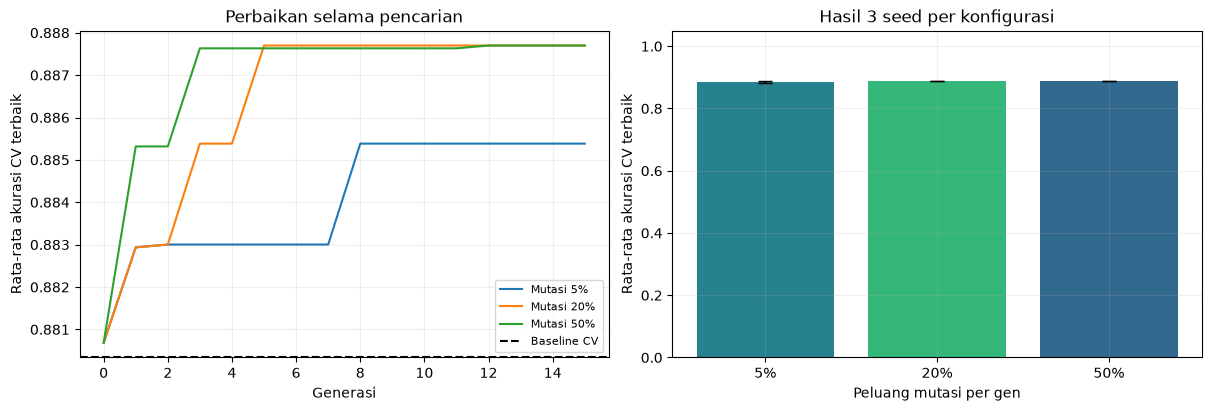

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
for mutation in MUTATION_VALUES:
    histories = np.vstack([r['history'] for r in model_runs if r['mutasi'] == mutation])
    axes[0].plot(histories.mean(axis=0), label=f'Mutasi {mutation:.0%}')
axes[0].axhline(baseline_cv, color='black', linestyle='--', label='Baseline CV')
axes[0].set(title='Perbaikan selama pencarian', xlabel='Generasi', ylabel='Rata-rata akurasi CV terbaik')
axes[0].legend(fontsize=8)
ordered = model_summary.sort_values('mutasi')
axes[1].bar(ordered['mutasi'].map(lambda v: f'{v:.0%}'), ordered['cv_rata_rata'],
            yerr=ordered['cv_std'], capsize=5, color=['#26828e', '#35b779', '#31688e'])
axes[1].set(title='Hasil 3 seed per konfigurasi', xlabel='Peluang mutasi per gen',
            ylabel='Rata-rata akurasi CV terbaik', ylim=(0, 1.05))
plt.show()

### 1.8 Buka ujian akhir satu kali

Pengaturan sudah dipilih. Sekarang baseline dan model hasil GA dilatih pada **seluruh data latihan**,
lalu diuji pada data uji yang tadi disimpan.

Kita melaporkan hasil apa adanya: tuning bisa menaikkan, menyamakan, atau menurunkan akurasi uji.
Nilai CV pemenang bisa optimistis karena dipilih dari banyak kandidat; nilai uji memberi pemeriksaan terpisah.
Jangan mengganti pengaturan lagi berdasarkan nilai uji ini.

,Model,Akurasi CV latihan,Akurasi uji,Benar / jumlah uji
0,Decision Tree bawaan,0.8804,0.9444,34 / 36
1,Decision Tree hasil GA,0.8877,0.9167,33 / 36


Selisih akurasi uji GA terhadap baseline: -2.78 poin persentase.


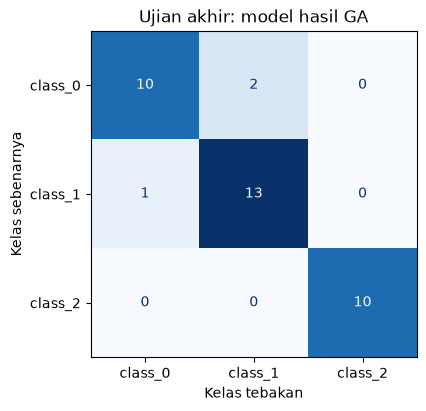

In [8]:
tuned_model = DecisionTreeClassifier(**chosen_model_run['params'], random_state=SEED_DATA)
baseline_model.fit(X_train, y_train)
tuned_model.fit(X_train, y_train)
pred_baseline = baseline_model.predict(X_test)
pred_tuned = tuned_model.predict(X_test)
baseline_test_accuracy = accuracy_score(y_test, pred_baseline)
tuned_test_accuracy = accuracy_score(y_test, pred_tuned)
model_comparison = pd.DataFrame({
    'Model': ['Decision Tree bawaan', 'Decision Tree hasil GA'],
    'Akurasi CV latihan': [baseline_cv, chosen_model_run['cv_terbaik']],
    'Akurasi uji': [baseline_test_accuracy, tuned_test_accuracy],
    'Benar / jumlah uji': [f'{int((y_test == p).sum())} / {len(y_test)}'
                          for p in [pred_baseline, pred_tuned]],
})
display(model_comparison.round(4))
delta_pp = (tuned_test_accuracy - baseline_test_accuracy) * 100
print(f'Selisih akurasi uji GA terhadap baseline: {delta_pp:+.2f} poin persentase.')

fig, ax = plt.subplots(figsize=(5, 4), layout='constrained')
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_tuned, display_labels=wine.target_names, ax=ax, cmap='Blues', colorbar=False
)
ax.set(title='Ujian akhir: model hasil GA', xlabel='Kelas tebakan', ylabel='Kelas sebenarnya')
ax.grid(False)
plt.show()

**Cara membaca kotak di atas:** baris adalah kelas sebenarnya, kolom adalah tebakan model.
Angka pada diagonal berarti tebakan benar; angka di luar diagonal berarti salah.
Data uji hanya 36 sampel, sehingga satu tebakan saja memengaruhi akurasi sekitar 2.78 poin persentase.
Hasil ini adalah demonstrasi pada satu pembagian data, bukan bukti bahwa GA selalu lebih unggul.

# 2. Vehicle Routing Problem (VRP)

### 2.1 Pahami cerita dan aturannya

Bayangkan ada **3 mobil pengantar**, **12 pelanggan**, dan satu gudang (**depot**, nomor 0).
Setiap mobil hanya dapat membawa **10 kotak**. Kita ingin mengantar semua pesanan dengan jarak total sekecil mungkin.

Ini adalah **Capacitated VRP (CVRP)**: VRP dengan batas kapasitas.
Berbeda dari contoh TSP satu perjalanan pada notebook referensi, di sini pesanan dibagi ke beberapa kendaraan.

Aturannya:

1. Semua pelanggan dikunjungi **tepat satu kali**.
2. Setiap rute berawal dan berakhir di depot.
3. Muatan setiap mobil tidak lebih dari 10 kotak; pesanan tidak dipecah.
4. Paling banyak 3 mobil digunakan, satu perjalanan per mobil.
5. Jarak adalah garis lurus pada peta buatan, dalam **satuan koordinat**, bukan jarak jalan nyata.

Tidak ada kemacetan, jam pengantaran, atau biaya kendaraan tambahan pada contoh ini.

### 2.2 Buat peta dan pesanan

`x` dan `y` menunjukkan posisi, sedangkan `permintaan` menunjukkan jumlah kotak.
Jarak dua titik dihitung seperti mengukur garis dengan penggaris.
Jumlah kapasitas armada harus cukup, tetapi itu saja belum menjamin pembagian rute pasti bisa dilakukan.

Total pesanan: 28 kotak | Kapasitas armada: 30 kotak


,x,y,permintaan
id,,,
0,0,0,0
1,2,7,2
2,-6,-2,2
3,5,-5,3
4,4,8,2
5,-5,-4,2
6,7,-4,3
7,1,5,2
8,-7,-3,2


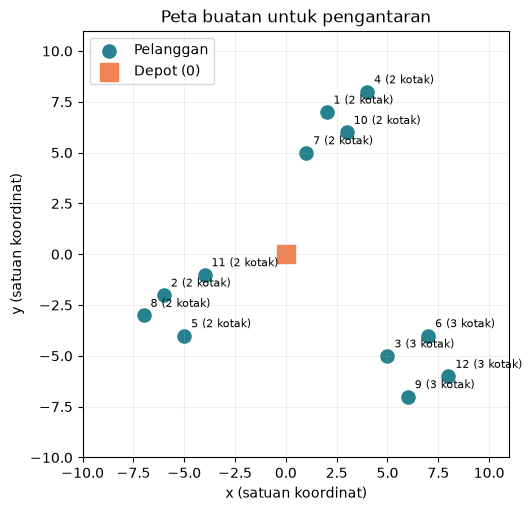

In [9]:
locations = pd.DataFrame({
    'id': list(range(13)),
    'x': [0, 2, -6, 5, 4, -5, 7, 1, -7, 6, 3, -4, 8],
    'y': [0, 7, -2, -5, 8, -4, -4, 5, -3, -7, 6, -1, -6],
    'permintaan': [0, 2, 2, 3, 2, 2, 3, 2, 2, 3, 2, 2, 3],
}).set_index('id')
CAPACITY = 10
MAX_VEHICLES = 3
CUSTOMERS = np.arange(1, len(locations))
coords = locations[['x', 'y']].to_numpy(dtype=float)
demands = locations['permintaan'].to_numpy(dtype=int)
DIST = np.linalg.norm(coords[:, None, :] - coords[None, :, :], axis=2)
assert demands[1:].max() <= CAPACITY
assert demands.sum() <= CAPACITY * MAX_VEHICLES
print(f'Total pesanan: {demands.sum()} kotak | Kapasitas armada: {CAPACITY * MAX_VEHICLES} kotak')
display(locations)

fig, ax = plt.subplots(figsize=(7, 5), layout='constrained')
ax.scatter(coords[1:, 0], coords[1:, 1], s=90, color='#26828e', label='Pelanggan')
ax.scatter(*coords[0], marker='s', s=180, color='#ef8354', label='Depot (0)')
for customer in CUSTOMERS:
    ax.annotate(f'{customer} ({demands[customer]} kotak)', coords[customer],
                xytext=(5, 6), textcoords='offset points', fontsize=8)
ax.set(title='Peta buatan untuk pengantaran', xlabel='x (satuan koordinat)', ylabel='y (satuan koordinat)')
ax.set_aspect('equal')
ax.margins(0.2)
ax.legend()
plt.show()

### 2.3 Ubah urutan pelanggan menjadi beberapa rute

Kromosom adalah urutan nomor pelanggan, misalnya `[1, 2, 3, ..., 12]`.
Semua nomor wajib ada satu kali, seperti menyusun kartu bernomor tanpa menggandakan kartu.

**Cara membagi rute (decoder greedy):** baca pelanggan dari kiri ke kanan.
Masukkan ke mobil saat ini jika masih muat. Jika tidak muat, mobil pulang dan pelanggan masuk mobil berikutnya.
Ini aturan sederhana; untuk urutan tertentu, pemisahan ini belum tentu yang paling pendek.
GA mengubah urutan pelanggan, lalu decoder membaginya kembali.

Decoder sementara dapat menghasilkan lebih dari 3 rute. Kandidat seperti itu diberi hukuman besar pada fitness.
Kita mulai dengan satu solusi valid dan mempertahankan elit agar selalu ada solusi valid yang tersimpan.

In [10]:
def decode_routes(chromosome):
    order = [int(c) for c in chromosome]
    if sorted(order) != CUSTOMERS.tolist():
        raise ValueError('Setiap pelanggan harus muncul tepat satu kali.')
    routes, current, load = [], [0], 0
    for customer in order:
        if load + demands[customer] > CAPACITY:
            routes.append(current + [0])
            current, load = [0], 0
        current.append(customer)
        load += demands[customer]
    routes.append(current + [0])
    return routes

def route_distance(route):
    return float(sum(DIST[a, b] for a, b in zip(route[:-1], route[1:])))

def evaluate_routes(chromosome):
    routes = decode_routes(chromosome)
    distance = sum(route_distance(route) for route in routes)
    excess = max(0, len(routes) - MAX_VEHICLES)
    return routes, distance, excess

baseline_order = CUSTOMERS.copy()
baseline_routes, baseline_distance, baseline_excess = evaluate_routes(baseline_order)
assert baseline_excess == 0, 'Baseline wajib layak sebelum pencarian dimulai.'
for vehicle, route in enumerate(baseline_routes, start=1):
    print(f'Mobil {vehicle}: {route} | muatan={demands[route].sum()} | jarak={route_distance(route):.2f}')
print(f'Jarak total baseline urutan nomor: {baseline_distance:.2f}')

Mobil 1: [0, 1, 2, 3, 4, 0] | muatan=9 | jarak=52.71
Mobil 2: [0, 5, 6, 7, 8, 0] | muatan=9 | jarak=48.15
Mobil 3: [0, 9, 10, 11, 12, 0] | muatan=10 | jarak=55.46
Jarak total baseline urutan nomor: 156.32


### 2.4 Buat fitness: dekat itu bagus, melanggar itu buruk

Kita menghitung:

**biaya = jarak total + penalti × jumlah mobil yang melebihi batas**  
**fitness = −biaya**

Misalnya jarak 50 menghasilkan fitness −50, lebih bagus daripada jarak 80 dengan fitness −80.
Penalti dipilih lebih besar dari batas atas jarak solusi valid, sehingga solusi melanggar tidak mengalahkan solusi valid.

Untuk 12 pelanggan dan paling banyak 3 rute, ada paling banyak `12 + 3` ruas perjalanan.
Setiap ruas paling panjang sebesar jarak maksimum pada matriks. Itulah dasar ukuran penalti di bawah.

In [11]:
PENALTY = float((len(CUSTOMERS) + MAX_VEHICLES) * DIST.max() + 1)

def fitness_vrp(ga_instance, solution, solution_idx):
    _, distance, excess = evaluate_routes(solution)
    return -(distance + PENALTY * excess)

print(f'Penalti per mobil berlebih: {PENALTY:.2f}')
print(f'Fitness baseline: {fitness_vrp(None, baseline_order, None):.2f}')

Penalti per mobil berlebih: 234.35
Fitness baseline: -156.32


### 2.5 Buat crossover dan mutasi yang menjaga nomor tetap lengkap

Crossover biasa dapat membuat nomor ganda. Kita menggunakan **Order Crossover (OX)**:

1. Ambil potongan urutan dari orang tua pertama.
2. Baca orang tua kedua secara melingkar mulai setelah potongan itu.
3. Isi tempat kosong dengan nomor yang belum dipakai, mengikuti urutan bacaan tadi.

Contoh dengan nomor kecil: ambil `[2, 3]` dari `[1, 2, 3, 4, 5]`,
lalu isi sisanya mengikuti orang tua kedua. Setiap nomor tetap muncul satu kali.

**Swap mutation** menukar dua nomor, seperti menukar posisi dua kartu.
Di kasus VRP, peluang mutasi berlaku **per kromosom**: jika terpilih, tukar satu pasang nomor.
Ini berbeda dari mutasi per gen pada kasus model, sehingga angkanya tidak dibandingkan langsung antarkasus.

In [12]:
def order_child(parent_a, parent_b, left, right):
    # Potongan memakai aturan Python: left termasuk, right tidak termasuk.
    child = np.full(len(parent_a), -1, dtype=int)
    child[left:right] = parent_a[left:right]
    used = set(child[left:right])
    scan_b = np.concatenate([parent_b[right:], parent_b[:right]])
    remaining = [int(g) for g in scan_b if g not in used]
    empty_positions = list(range(right, len(child))) + list(range(left))
    child[empty_positions] = remaining
    return child

parent_a = np.array([1, 2, 3, 4, 5])
parent_b = np.array([5, 4, 3, 2, 1])
print('Orang tua A:', parent_a)
print('Orang tua B:', parent_b)
print('Anak, mempertahankan posisi 1 sampai 2:', order_child(parent_a, parent_b, 1, 3))

def make_vrp_operators(rng, mutation_probability):
    def crossover_ox(parents, offspring_size, ga_instance):
        children = np.empty(offspring_size, dtype=int)
        for i in range(offspring_size[0]):
            a, b = rng.choice(len(parents), size=2, replace=False)
            left, right = sorted(rng.choice(offspring_size[1] + 1, size=2, replace=False))
            children[i] = order_child(parents[a], parents[b], left, right)
        return children

    def mutation_swap(offspring, ga_instance):
        for child in offspring:
            if rng.random() < mutation_probability:
                a, b = rng.choice(len(child), size=2, replace=False)
                child[a], child[b] = child[b], child[a]
        return offspring

    return crossover_ox, mutation_swap

Orang tua A: [1 2 3 4 5]
Orang tua B: [5 4 3 2 1]
Anak, mempertahankan posisi 1 sampai 2: [4 2 3 1 5]


### 2.6 Jalankan GA dan ulangi eksperimennya

Kita pakai **30 kandidat, 60 generasi, turnamen 3 kandidat, dan 2 elit**.
Peluang swap yang diuji adalah 5%, 20%, dan 50%, masing-masing untuk 3 seed: **9 percobaan**.
Untuk seed yang sama, populasi awalnya sama pada ketiga konfigurasi.
Baseline urutan nomor selalu dimasukkan sebagai satu anggota populasi awal.

**Aturan pemilihan:** pilih rata-rata jarak paling kecil, lalu simpangan baku terkecil,
lalu tingkat mutasi terkecil. Dari konfigurasi itu, ambil rute terbaik di antara 3 seed.
Berbeda dari machine learning, ini optimisasi satu peta yang sudah diketahui: tidak ada pembagian train/test.

In [13]:
def run_vrp_ga(mutation_probability, seed):
    rng = np.random.default_rng(seed)
    initial_population = np.vstack(
        [baseline_order.copy()] + [rng.permutation(CUSTOMERS) for _ in range(29)]
    )
    crossover_ox, mutation_swap = make_vrp_operators(rng, mutation_probability)
    started = perf_counter()
    ga = pygad.GA(
        num_generations=60, num_parents_mating=12,
        initial_population=initial_population, gene_type=int,
        gene_space=CUSTOMERS.tolist(), allow_duplicate_genes=False,
        fitness_func=fitness_vrp,
        parent_selection_type='tournament', K_tournament=3, keep_elitism=2,
        crossover_type=crossover_ox, mutation_type=mutation_swap,
        random_seed=seed,
    )
    ga.run()
    solution, fitness, _ = ga.best_solution()
    routes, distance, excess = evaluate_routes(solution)
    assert excess == 0, 'Hasil akhir melebihi jumlah mobil.'
    return {
        'mutasi': mutation_probability, 'seed': seed, 'jarak': distance,
        'mobil': len(routes), 'detik': perf_counter() - started,
        'kromosom': solution.copy(), 'routes': routes,
        # Elit valid selalu tersedia; biaya terbaik sama dengan jarak tanpa penalti.
        'history': -np.asarray(ga.best_solutions_fitness, dtype=float),
    }

vrp_runs = []
for mutation in MUTATION_VALUES:
    for seed in SEEDS:
        result = run_vrp_ga(mutation, seed)
        vrp_runs.append(result)
        print(f'Mutasi={mutation:.2f}, seed={seed}: jarak={result["jarak"]:.2f}, mobil={result["mobil"]}')
vrp_trials = pd.DataFrame([
    {k: r[k] for k in ['mutasi', 'seed', 'jarak', 'mobil', 'detik']} for r in vrp_runs
])
vrp_summary = vrp_trials.groupby('mutasi', as_index=False).agg(
    jarak_rata_rata=('jarak', 'mean'), jarak_std=('jarak', 'std'),
    jarak_terbaik=('jarak', 'min'), detik_rata_rata=('detik', 'mean'),
).sort_values(['jarak_rata_rata', 'jarak_std', 'mutasi'])
display(vrp_trials.round(3))
display(vrp_summary.round(3))
chosen_vrp_mutation = float(vrp_summary.iloc[0]['mutasi'])
chosen_vrp_run = sorted(
    [r for r in vrp_runs if r['mutasi'] == chosen_vrp_mutation],
    key=lambda r: (r['jarak'], r['seed'])
)[0]
print('Peluang swap terpilih:', chosen_vrp_mutation)

Mutasi=0.05, seed=11: jarak=78.05, mobil=3
Mutasi=0.05, seed=22: jarak=76.11, mobil=3


Mutasi=0.05, seed=33: jarak=74.68, mobil=3
Mutasi=0.20, seed=11: jarak=74.20, mobil=3


Mutasi=0.20, seed=22: jarak=74.20, mobil=3

Mutasi=0.20, seed=33: jarak=77.53, mobil=3
Mutasi=0.50, seed=11: jarak=74.20, mobil=3


Mutasi=0.50, seed=22: jarak=74.20, mobil=3


Mutasi=0.50, seed=33: jarak=76.96, mobil=3


,mutasi,seed,jarak,mobil,detik
0,0.05,11,78.053,3,0.042
1,0.05,22,76.110,3,0.041
2,0.05,33,74.680,3,0.037
3,0.20,11,74.199,3,0.042
4,0.20,22,74.199,3,0.039
5,0.20,33,77.532,3,0.042
6,0.50,11,74.199,3,0.042
7,0.50,22,74.199,3,0.044
8,0.50,33,76.956,3,0.047


,mutasi,jarak_rata_rata,jarak_std,jarak_terbaik,detik_rata_rata
2,0.50,75.118,1.592,74.199,0.045
1,0.20,75.310,1.924,74.199,0.041
0,0.05,76.281,1.693,74.680,0.040


Peluang swap terpilih: 0.5


### 2.7 Bandingkan hasil dan baca grafik

Kali ini **lebih rendah lebih bagus**, karena yang digambar adalah jarak.
Batang pembanding menunjukkan rata-rata hasil 3 seed; garis kecilnya adalah simpangan baku.
Baseline hanya mengunjungi pelanggan berdasarkan nomor, sehingga merupakan pembanding sederhana.

Tabel juga menampilkan rute terpilih. Nilainya adalah hasil satu run terpilih,
sedangkan grafik batang merangkum tiga run; keduanya tidak selalu sama.

,Metode,Jarak total,Jumlah mobil
0,Baseline urutan nomor,156.316,3
1,GA terpilih,74.199,3


Penghematan terhadap baseline urutan nomor: 52.53%


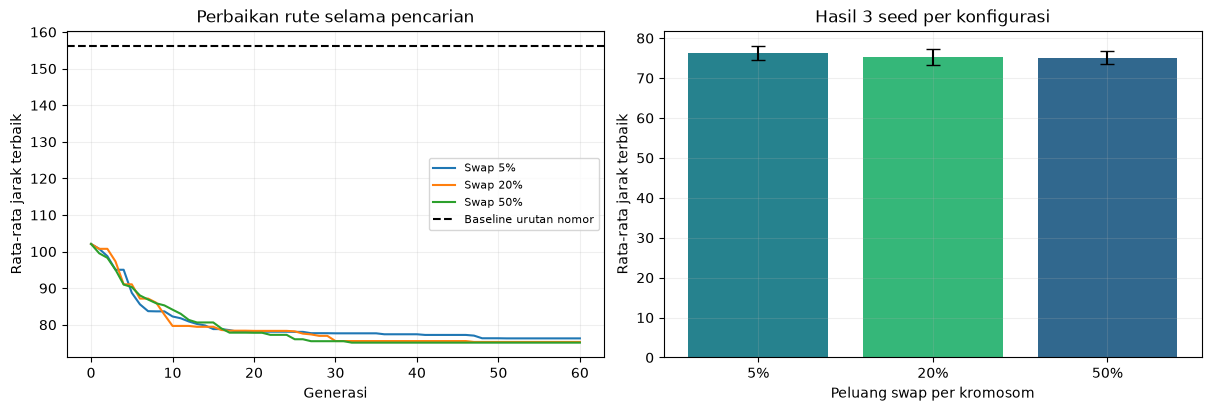

In [14]:
vrp_saving = 100 * (baseline_distance - chosen_vrp_run['jarak']) / baseline_distance
display(pd.DataFrame({
    'Metode': ['Baseline urutan nomor', 'GA terpilih'],
    'Jarak total': [baseline_distance, chosen_vrp_run['jarak']],
    'Jumlah mobil': [len(baseline_routes), len(chosen_vrp_run['routes'])],
}).round(3))
print(f'Penghematan terhadap baseline urutan nomor: {vrp_saving:.2f}%')

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
for mutation in MUTATION_VALUES:
    histories = np.vstack([r['history'] for r in vrp_runs if r['mutasi'] == mutation])
    axes[0].plot(histories.mean(axis=0), label=f'Swap {mutation:.0%}')
axes[0].axhline(baseline_distance, color='black', linestyle='--', label='Baseline urutan nomor')
axes[0].set(title='Perbaikan rute selama pencarian', xlabel='Generasi', ylabel='Rata-rata jarak terbaik')
axes[0].legend(fontsize=8)
ordered = vrp_summary.sort_values('mutasi')
axes[1].bar(ordered['mutasi'].map(lambda v: f'{v:.0%}'), ordered['jarak_rata_rata'],
            yerr=ordered['jarak_std'], capsize=5, color=['#26828e', '#35b779', '#31688e'])
axes[1].set(title='Hasil 3 seed per konfigurasi', xlabel='Peluang swap per kromosom',
            ylabel='Rata-rata jarak terbaik')
plt.show()

### 2.8 Periksa semua aturan sebelum menerima rute

Jarak pendek saja belum cukup. Kita cek: semua pelanggan dilayani satu kali,
semua mobil berangkat dan pulang ke depot, muatan tidak berlebih, dan mobil cukup.
`assert` adalah penjaga: notebook berhenti jika ada aturan yang gagal.

Tabel menampilkan isi tiap mobil. “Sisa kapasitas” berarti tempat kosong yang masih tersedia.

In [15]:
def validate_routes(routes):
    visited = [c for route in routes for c in route[1:-1]]
    assert sorted(visited) == CUSTOMERS.tolist(), 'Ada pelanggan hilang atau ganda.'
    assert len(routes) <= MAX_VEHICLES, 'Mobil terlalu banyak.'
    for route in routes:
        assert route[0] == route[-1] == 0, 'Rute harus berawal dan berakhir di depot.'
        assert len(route) > 2, 'Tidak boleh ada rute kosong.'
        assert demands[route].sum() <= CAPACITY, 'Muatan melebihi kapasitas.'
    return True

assert validate_routes(baseline_routes)
for run in vrp_runs:
    assert validate_routes(run['routes'])
    assert np.all(np.diff(run['history']) <= 1e-9), 'Elit terbaik tidak boleh memburuk.'
    assert run['jarak'] <= baseline_distance + 1e-9
best_routes = chosen_vrp_run['routes']
route_table = pd.DataFrame([
    {'Mobil': i, 'Rute': ' → '.join(map(str, route)),
     'Muatan': int(demands[route].sum()),
     'Sisa kapasitas': int(CAPACITY - demands[route].sum()),
     'Jarak': route_distance(route)}
    for i, route in enumerate(best_routes, start=1)
])
assert np.isclose(route_table['Jarak'].sum(), chosen_vrp_run['jarak'])
display(route_table.round(3))
print('LULUS: semua rute pada 9 percobaan memenuhi aturan VRP.')

,Mobil,Rute,Muatan,Sisa kapasitas,Jarak
0,1,0 → 10 → 4 → 1 → 7 → 11 → 0,10,0,25.350
1,2,0 → 2 → 8 → 5 → 3 → 0,9,1,27.096
2,3,0 → 6 → 12 → 9 → 0,9,1,21.754


LULUS: semua rute pada 9 percobaan memenuhi aturan VRP.


### 2.9 Gambar perjalanan setiap mobil

Warna berbeda berarti mobil berbeda. Kotak oranye adalah depot.
Panah menunjukkan arah perjalanan. Nomor di samping titik adalah nomor pelanggan.
Bandingkan peta baseline dan hasil GA untuk melihat perubahan pembagian pelanggan dan urutannya.

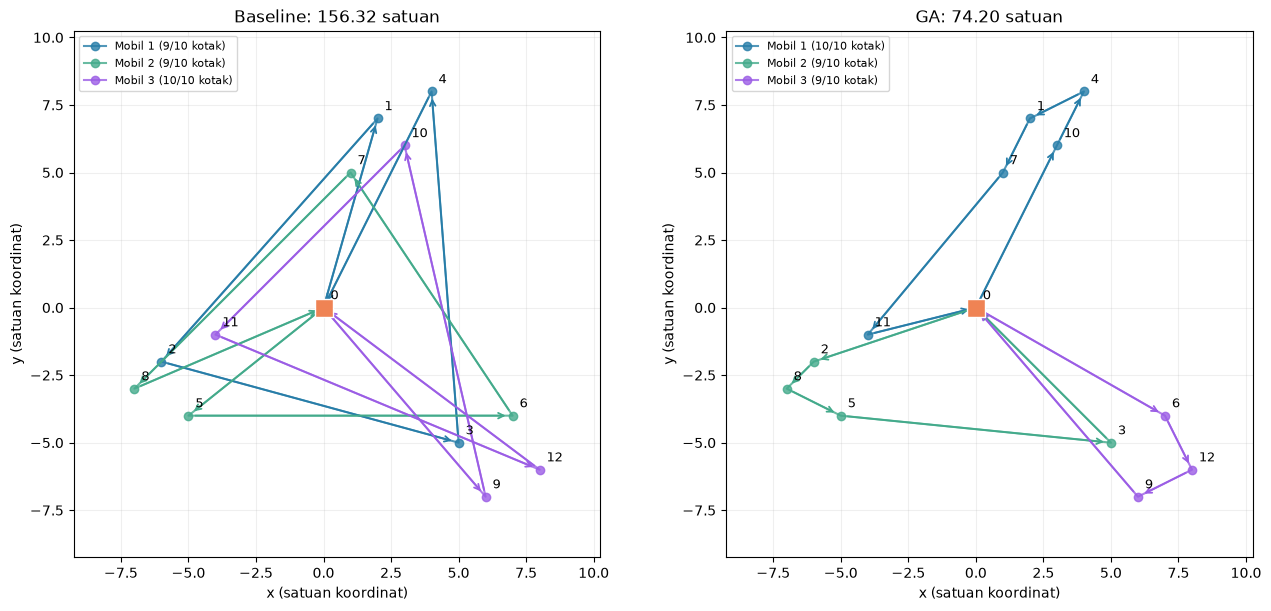

In [16]:
def plot_routes(ax, routes, title):
    colors = ['#277da8', '#43aa8b', '#9b5de5']
    for vehicle, (route, color) in enumerate(zip(routes, colors), start=1):
        points = coords[route]
        ax.plot(points[:, 0], points[:, 1], '-o', color=color,
                label=f'Mobil {vehicle} ({demands[route].sum()}/{CAPACITY} kotak)', alpha=0.8)
        for start, end in zip(points[:-1], points[1:]):
            ax.annotate('', xy=end, xytext=start,
                        arrowprops={'arrowstyle': '->', 'color': color, 'lw': 1.3,
                                    'shrinkA': 5, 'shrinkB': 5})
    ax.scatter(*coords[0], marker='s', s=170, color='#ef8354', edgecolors='white', zorder=5)
    for customer in range(len(coords)):
        ax.annotate(str(customer), coords[customer], xytext=(5, 6), textcoords='offset points', fontsize=9)
    ax.set(title=title, xlabel='x (satuan koordinat)', ylabel='y (satuan koordinat)')
    ax.set_aspect('equal')
    ax.margins(0.15)
    ax.legend(fontsize=8, loc='upper left')

fig, axes = plt.subplots(1, 2, figsize=(13, 6), layout='constrained')
plot_routes(axes[0], baseline_routes, f'Baseline: {baseline_distance:.2f} satuan')
plot_routes(axes[1], best_routes, f'GA: {chosen_vrp_run["jarak"]:.2f} satuan')
plt.show()

## 3. Pemeriksaan implementasi

Sebelum menyimpulkan, kita cek operator VRP pada banyak pasangan orang tua:
setelah digabung dan ditukar, semua nomor harus tetap lengkap.
Kita juga memastikan decoder menghitung perjalanan pulang, penalti menghukum mobil berlebih,
dan riwayat fitness model tetap berada pada rentang akurasi yang benar.

In [17]:
# Periksa operator dengan generator tersendiri agar tidak mengubah hasil eksperimen.
check_rng = np.random.default_rng(2026)
cross_check, swap_check = make_vrp_operators(check_rng, mutation_probability=1.0)
for _ in range(100):
    parents = np.vstack([check_rng.permutation(CUSTOMERS) for _ in range(4)])
    children = swap_check(cross_check(parents, (6, len(CUSTOMERS)), None), None)
    assert all(sorted(child.tolist()) == CUSTOMERS.tolist() for child in children)

# 0 → 1 → 0 harus menghitung dua arah, bukan hanya perjalanan pergi.
assert np.isclose(route_distance([0, 1, 0]), 2 * DIST[0, 1])
# Pengelompokan ini sengaja membutuhkan 4 mobil, sehingga harus dihukum.
infeasible_order = np.array([1, 2, 4, 5, 3, 6, 9, 12, 7, 8, 10, 11])
assert evaluate_routes(infeasible_order)[2] > 0
assert fitness_vrp(None, infeasible_order, None) < fitness_vrp(None, baseline_order, None)
for run in model_runs:
    assert np.all((run['history'] >= 0) & (run['history'] <= 1))
    assert np.all(np.diff(run['history']) >= -1e-12)
    assert np.isclose(run['history'][-1], run['cv_terbaik'])
print('LULUS: operator menjaga pelanggan unik; jarak pulang, penalti, dan riwayat fitness benar.')

LULUS: operator menjaga pelanggan unik; jarak pulang, penalti, dan riwayat fitness benar.


## 4. Kesimpulan otomatis dari hasil percobaan

Ringkasan di bawah mengambil angka langsung dari variabel hasil eksekusi,
sehingga tetap sesuai jika notebook dijalankan ulang.

In [18]:
direction = 'naik' if delta_pp > 0 else ('turun' if delta_pp < 0 else 'tetap')
display(Markdown(f"""
### Kasus 1 — Hyperparameter Tuning

- GA memilih pengaturan model: `{chosen_model_run['params']}`.
- Mutasi GA terpilih: **{chosen_model_mutation:.0%} per gen**, berdasarkan rata-rata CV tiga seed.
- CV baseline: **{baseline_cv:.2%}**; CV kandidat terpilih: **{chosen_model_run['cv_terbaik']:.2%}**.
- Akurasi uji baseline: **{baseline_test_accuracy:.2%}**; hasil GA: **{tuned_test_accuracy:.2%}**.
- Akurasi uji **{direction}**, dengan selisih **{delta_pp:+.2f} poin persentase**.

### Kasus 2 — VRP

- Peluang swap terpilih: **{chosen_vrp_mutation:.0%} per kromosom**, berdasarkan rata-rata jarak tiga seed.
- Jarak baseline: **{baseline_distance:.2f} satuan**; rute GA terpilih: **{chosen_vrp_run['jarak']:.2f} satuan**.
- Penghematan terhadap urutan nomor: **{vrp_saving:.2f}%**.
- Digunakan **{len(best_routes)} mobil**, dan semua batas kapasitas serta kunjungan telah diperiksa.
"""))


### Kasus 1 — Hyperparameter Tuning

- GA memilih pengaturan model: `{'max_depth': 5, 'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'criterion': 'entropy'}`.
- Mutasi GA terpilih: **20% per gen**, berdasarkan rata-rata CV tiga seed.
- CV baseline: **88.04%**; CV kandidat terpilih: **88.77%**.
- Akurasi uji baseline: **94.44%**; hasil GA: **91.67%**.
- Akurasi uji **turun**, dengan selisih **-2.78 poin persentase**.

### Kasus 2 — VRP

- Peluang swap terpilih: **50% per kromosom**, berdasarkan rata-rata jarak tiga seed.
- Jarak baseline: **156.32 satuan**; rute GA terpilih: **74.20 satuan**.
- Penghematan terhadap urutan nomor: **52.53%**.
- Digunakan **3 mobil**, dan semua batas kapasitas serta kunjungan telah diperiksa.


### Apa yang sudah dipelajari?

1. GA dapat mencari **paket pengaturan model** maupun **urutan kunjungan pelanggan**.
2. Cara menulis kromosom, fitness, crossover, dan mutasi harus sesuai dengan masalah.
3. Tuning perlu percobaan dan pembanding. Peluang mutasi yang lebih besar tidak otomatis lebih baik.
4. Tiga seed membantu melihat variasi akibat pengacakan GA, tetapi belum cukup untuk klaim statistik yang kuat.
5. Pada kasus model, data uji hanya dipakai setelah pemilihan selesai. Skor CV pemilihan bukan estimasi akhir yang bebas bias.
6. Pada VRP, hasil berlaku untuk peta contoh ini. Belum ada pembanding algoritma kuat atau pembuktian optimum global;
   decoder greedy juga membatasi cara urutan dibagi menjadi rute.

### Latihan lanjutan (opsional)

- Untuk mempelajari biaya pencarian, ubah **satu pengaturan saja**, misalnya generasi 15 menjadi 30 pada model
  atau 60 menjadi 120 pada VRP, lalu catat kualitas hasil dan waktunya.
- Untuk VRP, coba peta baru dan beberapa seed tambahan agar terlihat apakah pengaturan terpilih tetap bagus.
- Jika mengubah kapasitas atau permintaan, pastikan baseline masih valid sebelum menjalankan GA.
- Jika mengevaluasi model lebih jauh, siapkan data uji baru atau gunakan nested cross-validation;
  jangan terus memilih pengaturan berdasarkan data uji yang sudah dibuka.

### Referensi

- Contoh lokal: `05_applications_ga_checkpoint.ipynb` (alur penggunaan PyGAD).
- [PyGAD: parameter GA](https://pygad.readthedocs.io/en/stable/pygad.html).
- [PyGAD: operator crossover dan mutasi buatan sendiri](https://pygad.readthedocs.io/en/latest/user_defined_operators.html).
- [scikit-learn: dataset Wine](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html).
- [scikit-learn: mencegah kebocoran data](https://scikit-learn.org/stable/common_pitfalls.html).